***
# Plotting with Matplotlib

- Matplotlib is the standard plotting library for Python
- Not part of core Python, needs to be installed (e.g., via Anaconda) and imported:

    ```python
    import matplotlib.pyplot as plt
    ```
- Higher-level alternative: [seaborn](https://seaborn.pydata.org/)

***
## Line plots

### Plot single lines

- Use
  [`plot()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html)
- Assign the last plotting call's result to `_` to suppress its text output;
  the plot still appears.

*Example: plotting a single line*

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Plot the quadratic function $y = x^{2}$ on the interval `[-1, 1]`:

1. Create a grid of 50 $x$-values using
   [`np.linspace()`](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html).
2. Compute the corresponding $y$-values and plot them.
</div>
<span style="display: none;">YourTurnEnd</span>

In [14]:
import matplotlib.pyplot as plt
import numpy as np

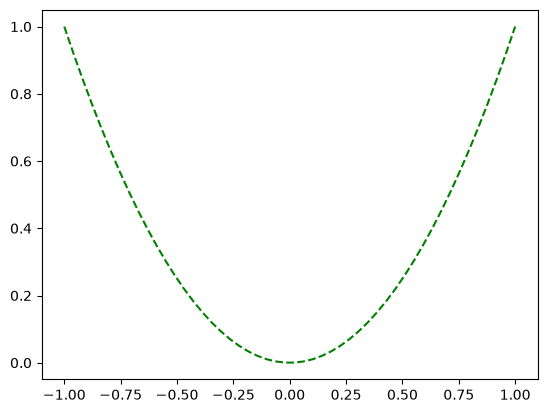

In [ ]:
x = np.linspace(-1,1,50)
y = x**2.0
plt.plot(x,y, color = 'green', ls = '--')

### Plotting multiple lines & plot styles

*Main colors*
(see [here](https://matplotlib.org/stable/tutorials/colors/colors.html) for details,
    see [here](https://matplotlib.org/stable/gallery/color/named_colors.html#base-colors) for list of named colors):

- `b`: blue
- `g`: green
- `r`: red
- `c`: cyan
- `m`: magenta
- `y`: yellow
- `k`: black
- `w`: white

*Line styles:*

-   `-` solid line
-   `--` dashed line
-   `-.` dash-dotted line
-   `:` dotted line

*Marker styles ([complete list](https://matplotlib.org/stable/api/markers_api.html)):*

- `o`: circle
- `s`: square
- `*`: star
- `x`: x
- `d`: (thin) diamond

*Example: styling with keyword arguments*

-   See section on _Other Parameters_ in [`plot()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html)
-   Keyword arguments can be abbreviated:

    - `c` or `color`
    - `ls` or `linestyle`
    - `lw` or `linewidth`
    - `ms` or `markersize`

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Use the data files located in the folder `../../data/FRED` to perform the following tasks:

1. Load the data from `FRED_annual.csv`. The file contains annual observations
   on selected macroeconomic variables for the US.
2. Plot the unemployment rate (column `UNRATE`) using a blue dashed line with line width 0.5 and the inflation rate (column `INFLATION`) using an orange line with line width 0.75 in the *same* figure.
</div>
<span style="display: none;">YourTurnEnd</span>

   Year     GDP   CPI  UNRATE  FEDFUNDS  INFLATION
0  1954  2877.7  26.9     5.6       1.0        NaN


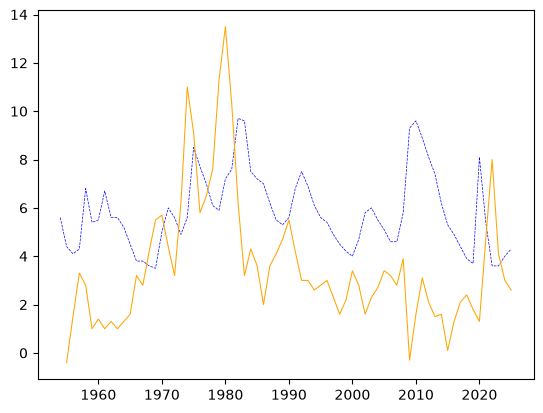

In [ ]:
import pandas as pd

DATA_PATH = '../../data'
file = f'{DATA_PATH}/FRED/FRED_annual.csv'

df = pd.read_csv(file)

print(df.head(1))

unrate = df['UNRATE']
inflation = df['INFLATION']
x = df['Year']       

plt.plot(x,unrate, c = 'blue', ls='--',lw = 0.5)
plt.plot(x,inflation, c = 'orange',lw = 0.75)

***
## Scatter plots

- Use [`scatter()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) 

*Example: Scatter y-values randomly drawn from [0, 1)*

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# Number of points
N = 50

# Create 50 uniformly spaced values on the unit interval
xvalues = np.linspace(0.0, 1.0, N)
# Draw random numbers from the interval [0, 1)
yvalues = np.random.default_rng(seed=123).random(N)

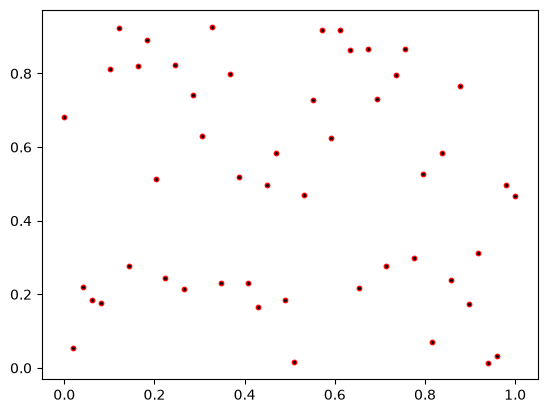

In [ ]:
plt.scatter(xvalues, yvalues, c='black', edgecolors = 'red', s = 10)

*Example: Scatter with marker areas randomly drawn from [0, 150)*

- The `s` argument specifies marker area in points squared.

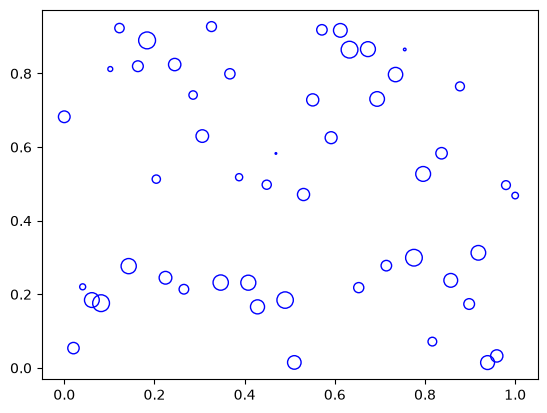

In [ ]:
# Draw random marker areas in points squared
size = np.random.default_rng(seed=456).random(N) * 150.0

#Create scatter plot with different size for each point

plt.scatter(xvalues, yvalues, s=size, color='none', edgecolors = 'blue')

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Use the data files located in the folder `../../data/FRED` to perform the following
tasks:

1. Load the data in `FRED_monthly.csv`. The file contains monthly observations
   on selected macroeconomic variables for the US.
2. Create a scatter plot of the real interest rate (column `REALRATE`) on the y-axis
   against the federal funds rate (column `FEDFUNDS`) on the x-axis.
   Specify the arguments `edgecolors='blue'` and `color='none'` to plot the data as
   blue rings.
</div>
<span style="display: none;">YourTurnEnd</span>

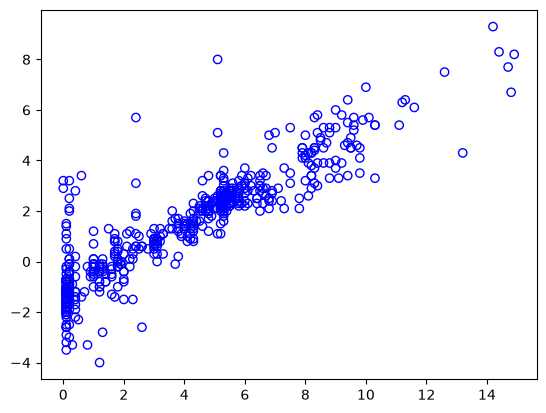

In [48]:
file = f'{DATA_PATH}/FRED/FRED_monthly.csv'

df = pd.read_csv(file)
df.head(1)

#scatter REALRATE vs FEDFUNDS
realrate = df['REALRATE']
fedfunds = df['FEDFUNDS']

x = df['Year']    

plt.scatter(fedfunds, realrate, edgecolors='blue', color = 'none')


***

## Histograms

- Use [`hist()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html)

*Example: Histogram of normal draws*

- Draw 10,000 points from the standard-normal distribution and plot a histogram.

In [51]:
import matplotlib.pyplot as plt
import numpy as np

# Draw 10,000 standard-normal numbers
x = np.random.default_rng(seed=1234).normal(size=10_000)

Text(0.5, 0, 'Realized random number')

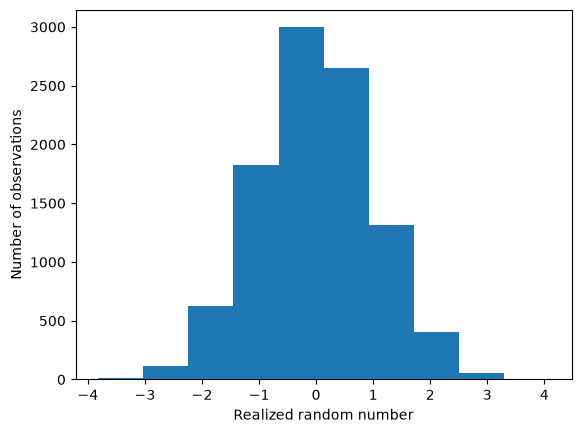

In [54]:
_ = plt.hist(x)
plt.ylabel('Number of observations')
plt.xlabel('Realized random number')

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">
Your turn</p>

Load the house-price data from `../../data/ames_houses.csv`. The column
`SalePrice` contains sale prices in thousands of US dollars.

1. Create a histogram of `SalePrice` with 10 bins. Label the axes
   "Sale price (thousands of USD)" and "Number of houses".
2. Change the number of bins to 50 and rerun the plotting code, keeping the
   data unchanged.
3. Why are the bars generally shorter with more bins?
</div>
<span style="display: none;">YourTurnEnd</span>

***
## Plotting categorical data

- Create bar charts with [`bar()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.bar.html)

*Example: Population sizes by municipality*

In [ ]:
import numpy as np

# Define category labels
municipality = ['Oslo', 'Bergen', 'Trondheim', 'Stavanger']
# Population on January 1, 2025, in thousands
population = np.array([724290, 293709, 216518, 150123]) / 1000

In [ ]:
plt.bar(municipality, population)

*Example: Horizontal bar charts*

- Use [`barh()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.barh.html)

***
## Adding labels and annotations

-   Titles: [`title()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.title.html) 
    and 
    [`suptitle()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.suptitle.html) 
-   Axes labels:
    [`xlabel()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xlabel.html) 
    and 
    [`ylabel()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.ylabel.html)
-   Legend: 
    [`legend()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.legend.html)
-   Add text at arbitrary position: 
    [`text()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.text.html)

*Example: Create graph with titles, axes labels, legend, and text*

Text(0, 0, 'Inserted text')

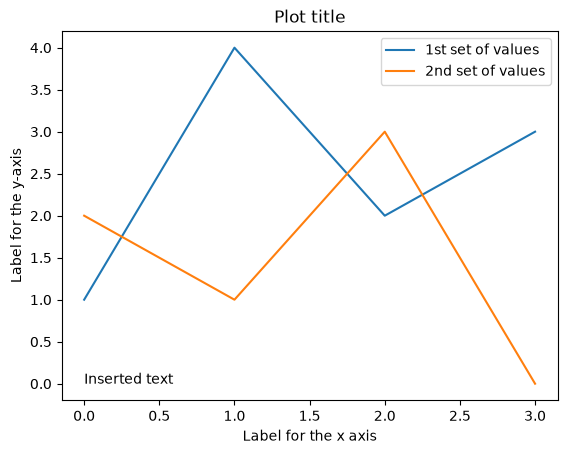

In [64]:
# Demo data used for plotting
xvalues = [0, 1, 2, 3]
yvalues = [1, 4, 2, 3]
yvalues2 = [2.0, 1.0, 3.0, 0.0]

plt.plot(xvalues, yvalues, label = '1st set of values')
plt.plot(xvalues, yvalues2, label = '2nd set of values')


plt.title('Plot title')
plt.xlabel('Label for the x axis')
plt.ylabel('Label for the y-axis')
plt.legend(loc = 'best')
plt.text(0, 0, 'Inserted text')

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">
Your turn</p>

A bakery in Bergen sells skillingsboller (cinnamon buns) for NOK 25 each.
Its fixed cost is NOK 60, and each bun costs NOK 10 to produce. For a quantity
$q$ produced and sold, revenue is $R(q) = 25q$ and total cost is
$C(q) = 60 + 10q$.

1. Create a grid of 50 quantities from 0 to 10 using
   [`np.linspace()`](
   https://numpy.org/doc/stable/reference/generated/numpy.linspace.html).
   Compute revenue and total cost for each quantity, then plot both in the same graph.
2. Add a descriptive title and label the axes "Quantity" and
   "Revenue / cost (NOK)".
3. Set `label=` when plotting each line, then use
   [`plt.legend()`](
   https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.legend.html)
   to display a legend identifying "Revenue" and "Total cost".
4. The lines intersect at quantity 4 and revenue/cost NOK 100. Mark this point
   with a black dot.
5. Use
   [`plt.text()`](
   https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.text.html)
   to place "Break-even" near this point without covering either line.

For which quantities does the bakery make a profit?
</div>
<span style="display: none;">YourTurnEnd</span>

***
## Plot limits, ticks, and tick labels

-   Plot limits:
    [`xlim()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xlim.html)
    and
    [`ylim()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.ylim.html)
-   Ticks and tick labels:
    [`xticks()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xticks.html)
    and
    [`yticks()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.yticks.html)

*Example: sine function plotted on $[0, 2\pi]$*

-   Add $x$-ticks at positions 0, $\pi$, and $2\pi$

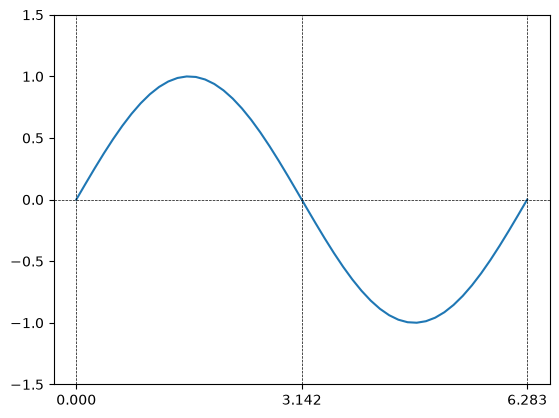

In [74]:
import numpy as np

# Create data using the sine function
xvalues = np.linspace(0.0, 2 * np.pi, 50)
yvalues = np.sin(xvalues)

# Define tick positions
xticks = [0.0, np.pi, 2 * np.pi]
# Define tick labels (can use LaTeX code!)
xtick_labels = ['0', r'$\pi$', r'$2\pi$']

plt.plot(xvalues, yvalues)

plt.ylim((-1.5,1.5))
_=plt.xticks(xticks)

plt.axhline(0,color='black',ls='--',lw=0.5)
plt.axvline(0,color='black',ls='--',lw=0.5)
plt.axvline(np.pi,color='black',ls='--',lw=0.5)
plt.axvline(np.pi*2,color='black',ls='--',lw=0.5)

***

## Adding straight lines

- Horizontal lines: [`axhline()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axhline.html)
- Vertical lines: [`axvline()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axvline.html)
- Other: [`axline()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axline.html#matplotlib.pyplot.axline)

*Example: Adding horizontal and vertical lines*

- Add horizontal line at 0, vertical lines at $\left[\frac{1}{2}\pi, \frac{3}{2}\pi\right]$ to previous sine function plot

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">
Your turn</p>

Plot the function $y=(x-1)^{2}$ on the interval [0, 2]:

1. Create a grid of 50 $x$-values using
   [`np.linspace()`](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html).
2. Compute and plot the $y$-values.
3. Label the $x$- and $y$-axes with *"x"* and *"y"*.
4. Add the title `"y = (x-1)^2"`.
5. Add a vertical line at $x=1$ using a dashed line style.
</div>
<span style="display: none;">YourTurnEnd</span>

***
## Object-oriented interface

- Useful for reusable code and figures with multiple subplots.
- Explicit references to the figure and axes make plots easier to customize
  and reuse, including single graphs.
- Operate on instances of [`Figure`](https://matplotlib.org/stable/api/figure_api.html)
    and [`Axes`](https://matplotlib.org/stable/api/axes_api.html) objects
- Objects are created with [`subplots()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html) function:
    ```python
    fig, ax = plt.subplots()
    ```
- See Matplotlib's
  [API guide](https://matplotlib.org/stable/users/explain/figure/api_interfaces.html)
  for a comparison of the pyplot and object-oriented interfaces.

### Example: annotations in pyplot vs. object-oriented interface

#### pyplot interface

-   This repeats the annotations example from above

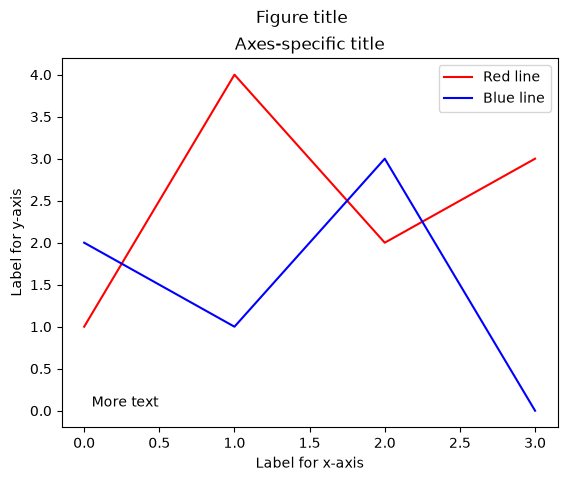

In [75]:
import matplotlib.pyplot as plt

# Demo data used for plotting
xvalues = [0, 1, 2, 3]
yvalues = [1, 4, 2, 3]
yvalues2 = [2.0, 1.0, 3.0, 0.0]

plt.plot(xvalues, yvalues, color='red')
plt.plot(xvalues, yvalues2, color='blue')

# Add titles, labels, legend, and text
plt.suptitle('Figure title')
plt.title('Axes-specific title')
plt.xlabel('Label for x-axis')
plt.ylabel('Label for y-axis')
# This labels-only form is discouraged: labels depend on plotting order.
# Prefer label= in plt.plot(), followed by plt.legend().
plt.legend(['Red line', 'Blue line'])
# Adds text at data coordinates (0.05, 0.05)
_ = plt.text(0.05, 0.05, 'More text')

#### Object-oriented interface

Text(0.05, 0.05, 'More text')

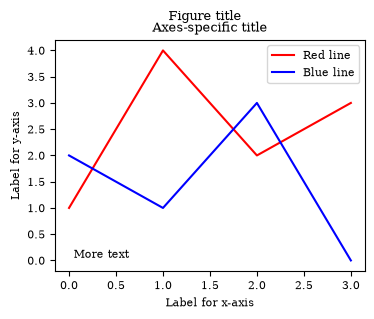

In [8]:
import matplotlib.pyplot as plt

# Create Figure and Axes objects
fig, ax = plt.subplots()

ax.plot(xvalues, yvalues, color='red', label='Red line')
ax.plot(xvalues, yvalues2, color='blue', label='Blue line')

# Add titles, labels, legend, and text
fig.suptitle('Figure title')  # Alternative: plt.suptitle()
ax.set_title('Axes-specific title')  # Alternative: plt.title()
ax.set_xlabel('Label for x-axis')  # Alternative: plt.xlabel()
ax.set_ylabel('Label for y-axis')  # Alternative: plt.ylabel()
ax.legend()  # Alternative: plt.legend()
# Adds text at data coordinates (0.05, 0.05)
_ = ax.text(0.05, 0.05, 'More text')  # Alternative: plt.text()

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">
Your turn</p>

Recall the example from above in which we drew from a normal distribution and visualized
the sample using a histogram.

1. Repeat these steps, but create the histogram using the object-oriented Matplotlib
   interface.
2. Set the x-axis label to 'Realized random number' and the y-axis label to 'Number of
   observations'.
3. Add the title 'Histogram of normal draws'.

</div>
<span style="display: none;">YourTurnEnd</span>

***
## Working with multiple plots (axes)

- Use [`subplots()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html) to obtain multiple sub-plots (axes)

*Example: Create a plot with 2 panels*

- Plot 1st and 2nd-degree polynomials

*Example: Create a figure with 2 rows and 2 columns*

- Plot polynomials of degrees 1 to 4
- Use `sharex` and `sharey` to enforce identical axes limits

Text(0.5, 1.0, 'Quadratic function')

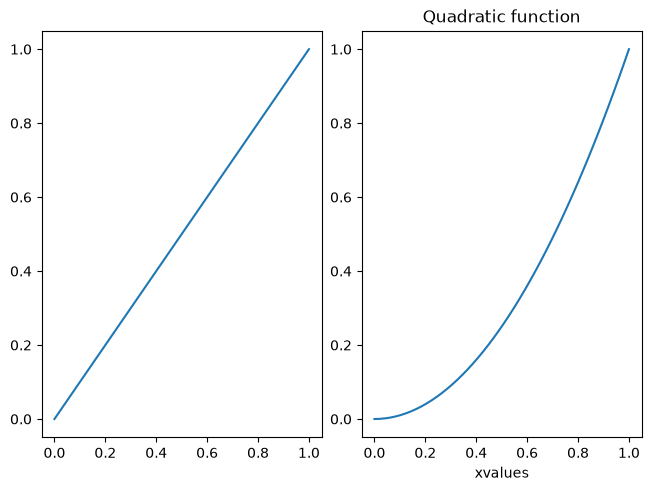

In [80]:
fig, axes = plt.subplots(1, 2, layout='constrained')
xvalues = np.linspace(0, 1, 50)

yvalues1 = xvalues

yvalues2 = xvalues**2
#Plot linear function into the first axis
axes[0].plot(xvalues,yvalues1)
#Plot quadratic function into second axis
axes[1].plot(xvalues,yvalues2)
axes[1].set_xlabel('xvalues')
axes[1].set_title('Quadratic function')

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">
Your turn</p>

Create a figure with 3 columns (on a single row) and plot the following functions
on the interval [0, 6]:

1. Subplot 1: $y = \sin(x)$
2. Subplot 2: $y = \sin(2 \cdot x)$
3. Subplot 3: $y = \sin(4 \cdot x)$

*Hint:* Use NumPy's
[`np.sin()`](https://numpy.org/doc/stable/reference/generated/numpy.sin.html)
function.
</div>
<span style="display: none;">YourTurnEnd</span>

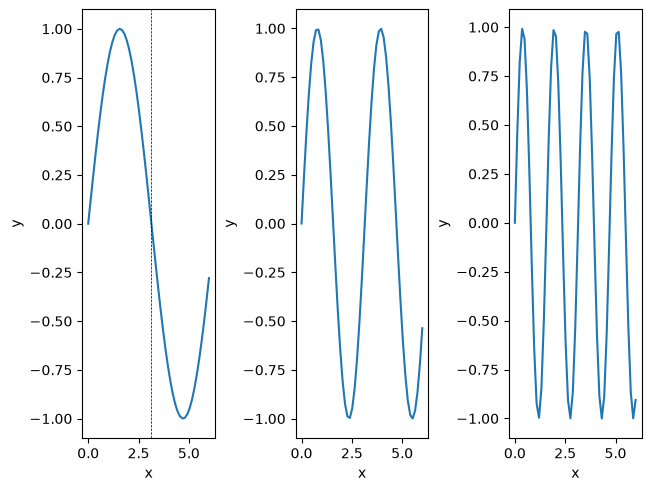

In [94]:
fig, axes = plt.subplots(1, 3, layout='constrained')

xvalues = np.linspace(0, 6, 51)
yvalues1 = np.sin(xvalues)
yvalues2 = np.sin(2 * xvalues)
yvalues3 = np.sin(4 * xvalues)

axes[0].plot(xvalues, yvalues1)
axes[1].plot(xvalues, yvalues2)
axes[2].plot(xvalues, yvalues3)

axes[0].set_xlabel('x')
axes[0].set_ylabel('y')

axes[1].set_xlabel('x')
axes[1].set_ylabel('y')


axes[2].set_xlabel('x')
axes[2].set_ylabel('y')

axes[0].axvline(np.pi,color='black',ls='--',lw=0.5)



***
# Plotting with pandas

 - Pandas provides convenience functions for plotting


## Bar charts with pandas

- Use pandas's [`plot.bar()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html):

*Example: Plot population of 15 largest municipalities in Norway*

- Keep the first 15 rows (the data are sorted by population).
- Rotate the x-axis tick labels by 45 degrees and align them to the right.

In [ ]:
import pandas as pd

# Path to local data/ folder
DATA_PATH = '../../data'

# Path to municipality data
filepath = f'{DATA_PATH}/ssb/municipalities.csv'

# Read only the municipality names and population numbers
df = pd.read_csv(filepath, usecols=['municipality', 'population'])

***
## Plotting time series data

- Use
[`DataFrame.plot()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.html) 

*Example: Plot US unemployment rate*

- Use circular markers with marker size 3.

In [10]:
# Path to annual FRED data; DATA_PATH variable was defined above!
filepath = f'{DATA_PATH}/FRED/FRED_annual.csv'

# Read CSV data
df = pd.read_csv(filepath, sep=',')

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">
Your turn</p>

Use the data files located in the folder `../../data/FRED` to perform the following
tasks:

1. Load the macroeconomic time series data from `FRED_monthly_all.csv`.

   *Hint:* Use `pd.read_csv(..., parse_dates=['DATE'], index_col='DATE')` to
   automatically parse strings stored in the `DATE` column as dates and set `DATE` as
   the index.
2. Create a line plot, showing both the unemployment rate `UNRATE`
   and the inflation rate `INFLATION` in a single graph.
</div>
<span style="display: none;">YourTurnEnd</span>

***
## Scatter plots with pandas

### Bivariate scatter plots

- Use [`DataFrame.plot.scatter()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.scatter.html)

*Example: Plot inflation vs. unemployment rate*

In [11]:
# Path to annual FRED data; DATA_PATH variable was defined above!
filepath = f'{DATA_PATH}/FRED/FRED_annual.csv'

# Read CSV data
df = pd.read_csv(filepath, sep=',')

### Scatter plots of more than two variables

- Use [`scatter_matrix()`](https://pandas.pydata.org/docs/reference/api/pandas.plotting.scatter_matrix.html)


*Example: plot unemployment rate vs. inflation vs. Fed Funds Rate*

In [12]:
from pandas.plotting import scatter_matrix

# Columns to include in plot
columns = ['UNRATE', 'INFLATION', 'FEDFUNDS']

***
## Box plots with pandas

- Use
[`DataFrame.plot.box()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.box.html)
- Shows median, interquartile range (25th to 75th percentile) and outliers

*Example: Unemployment rate, inflation, and Fed Funds Rate*

In [13]:
# Path to annual FRED data; DATA_PATH variable was defined above!
filepath = f'{DATA_PATH}/FRED/FRED_annual.csv'

# Read CSV data
df = pd.read_csv(filepath, sep=',')